In [20]:

# ==========================================================
# INSTALL / IMPORTS
# ==========================================================

!pip install timm imagehash -q

import os
import random
import time
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
import timm

from tqdm import tqdm
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("Imports completed.")


Imports completed.


In [21]:

# ==========================================================
# 1. REPRODUCIBILITY + DEVICE
# ==========================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("DEVICE / REPRODUCIBILITY")
print("=" * 70)
print("Device:", device)
print("Seed  :", SEED)

if torch.cuda.is_available():
    print("GPU   :", torch.cuda.get_device_name(0))


DEVICE / REPRODUCIBILITY
Device: cuda
Seed  : 42
GPU   : Tesla T4


# Experiment: Train on Real → Validate on Real → Test on Synthetic

**Purpose:** Evaluate the hybrid DenseNet169 + ViT-Tiny model when training and model selection use only real MRI data, while the final evaluation is performed on unseen synthetic MRI data.

- **Training:** Real MRI images
- **Validation:** Held-out real MRI images
- **Testing:** Synthetic MRI images only
- Synthetic test images are **never used for training, validation, checkpoint selection, or hyperparameter tuning**.


In [22]:

# ==========================================================
# 2. AUTOMATIC DATASET DISCOVERY
# ==========================================================

IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

# Optional manual paths. Leave as None for automatic detection.
MANUAL_REAL_DIR = None
MANUAL_SYNTHETIC_DIR = None


def has_images_in_class_folders(path):
    if not os.path.isdir(path):
        return False

    class_dirs = [
        os.path.join(path, d)
        for d in os.listdir(path)
        if os.path.isdir(os.path.join(path, d))
    ]

    if len(class_dirs) < 2:
        return False

    return any(
        f.lower().endswith(IMG_EXTS)
        for d in class_dirs
        for f in os.listdir(d)
    )


def is_split_root(path, required_splits=("train", "val")):
    if not os.path.isdir(path):
        return False

    return all(
        os.path.isdir(os.path.join(path, split))
        and has_images_in_class_folders(os.path.join(path, split))
        for split in required_splits
    )


def collect_candidates(base_dir="/kaggle/input"):
    split_roots = []
    class_roots = []

    if not os.path.isdir(base_dir):
        return split_roots, class_roots

    for root, dirs, files in os.walk(base_dir):
        # Avoid extremely deep / irrelevant cache directories.
        dirs[:] = [d for d in dirs if not d.startswith(".")]

        if is_split_root(root, ("train", "val")):
            split_roots.append(root)

        if has_images_in_class_folders(root):
            class_roots.append(root)

    return sorted(set(split_roots)), sorted(set(class_roots))


def score_real_candidate(path):
    s = path.lower()
    score = 0

    if "real" in s:
        score += 8
    if "clean" in s:
        score += 4
    if "final_dataset" in s:
        score += 5
    if "brain-tumour" in s or "brain_tumor" in s:
        score += 4
    if "synthetic" in s or "generated" in s:
        score -= 15
    if "mri-syntheticdata" in s:
        score -= 15

    return score


def score_synthetic_candidate(path):
    s = path.lower()
    score = 0

    if "synthetic" in s:
        score += 12
    if "generated" in s:
        score += 5
    if "mri-syntheticdata" in s:
        score += 8
    if "prepared_dataset" in s:
        score += 5
    if "real" in s and "synthetic" not in s:
        score -= 5

    return score


split_roots, class_roots = collect_candidates("/kaggle/input")

print("=" * 70)
print("AUTO-DISCOVERY")
print("=" * 70)
print("Split roots found:", len(split_roots))
print("Class roots found:", len(class_roots))

if MANUAL_REAL_DIR is not None:
    REAL_DIR = MANUAL_REAL_DIR
else:
    real_candidates = [
        p for p in split_roots
        if score_real_candidate(p) >= 0
    ]

    if not real_candidates:
        # Fallback: class-folder roots that are not obviously synthetic.
        real_candidates = [
            p for p in class_roots
            if score_real_candidate(p) >= 0
        ]

    if not real_candidates:
        raise FileNotFoundError(
            "Could not automatically find the real MRI dataset. "
            "Set MANUAL_REAL_DIR to the dataset path."
        )

    REAL_DIR = max(real_candidates, key=score_real_candidate)


if MANUAL_SYNTHETIC_DIR is not None:
    SYNTHETIC_DIR = MANUAL_SYNTHETIC_DIR
else:
    synthetic_candidates = [
        p for p in split_roots
        if score_synthetic_candidate(p) > 0
    ]

    if not synthetic_candidates:
        synthetic_candidates = [
            p for p in class_roots
            if score_synthetic_candidate(p) > 0
        ]

    if not synthetic_candidates:
        raise FileNotFoundError(
            "Could not automatically find the synthetic MRI dataset. "
            "Set MANUAL_SYNTHETIC_DIR to the dataset path."
        )

    SYNTHETIC_DIR = max(
        synthetic_candidates,
        key=score_synthetic_candidate
    )


# If a split root itself was selected, keep it.
# Otherwise the real directory may already contain train/val.
REAL_TRAIN_DIR = os.path.join(REAL_DIR, "train")
REAL_VAL_DIR = os.path.join(REAL_DIR, "val")

SYNTHETIC_TEST_DIR = os.path.join(SYNTHETIC_DIR, "test")

print("\n" + "=" * 70)
print("SELECTED DATASETS")
print("=" * 70)
print("REAL_DIR          :", REAL_DIR)
print("REAL_TRAIN_DIR    :", REAL_TRAIN_DIR)
print("REAL_VAL_DIR      :", REAL_VAL_DIR)
print("SYNTHETIC_DIR     :", SYNTHETIC_DIR)
print("SYNTHETIC_TEST_DIR:", SYNTHETIC_TEST_DIR)


AUTO-DISCOVERY
Split roots found: 1
Class roots found: 4

SELECTED DATASETS
REAL_DIR          : /kaggle/input/datasets/ramanarasimhakanduri/brain-tumour-dataset/final_dataset_clean
REAL_TRAIN_DIR    : /kaggle/input/datasets/ramanarasimhakanduri/brain-tumour-dataset/final_dataset_clean/train
REAL_VAL_DIR      : /kaggle/input/datasets/ramanarasimhakanduri/brain-tumour-dataset/final_dataset_clean/val
SYNTHETIC_DIR     : /kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset
SYNTHETIC_TEST_DIR: /kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset/test


In [23]:

# ==========================================================
# 3. BUILD REAL TRAIN/VALIDATION + SYNTHETIC TEST
# ==========================================================

def list_class_images(root):
    records = []

    if not os.path.isdir(root):
        return records

    classes = sorted([
        d for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d))
    ])

    for cls in classes:
        class_dir = os.path.join(root, cls)

        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith(IMG_EXTS):
                records.append([
                    os.path.join(class_dir, filename),
                    cls
                ])

    return records


# ----------------------------------------------------------
# CASE A: Real dataset already has train/val.
# ----------------------------------------------------------

if os.path.isdir(REAL_TRAIN_DIR) and os.path.isdir(REAL_VAL_DIR):

    real_train_records = list_class_images(REAL_TRAIN_DIR)
    real_val_records = list_class_images(REAL_VAL_DIR)

    real_train_df = pd.DataFrame(
        real_train_records,
        columns=["filepaths", "labels"]
    )

    real_val_df = pd.DataFrame(
        real_val_records,
        columns=["filepaths", "labels"]
    )

    print("Using existing real train/val split.")

# ----------------------------------------------------------
# CASE B: Real dataset is one class-folder root.
# Create stratified 80/20 REAL train/validation split.
# ----------------------------------------------------------

else:

    real_records = list_class_images(REAL_DIR)

    if len(real_records) == 0:
        raise FileNotFoundError(
            "No real images found. Check REAL_DIR."
        )

    real_df = pd.DataFrame(
        real_records,
        columns=["filepaths", "labels"]
    )

    real_train_df, real_val_df = train_test_split(
        real_df,
        test_size=0.20,
        stratify=real_df["labels"],
        random_state=SEED
    )

    real_train_df = real_train_df.reset_index(drop=True)
    real_val_df = real_val_df.reset_index(drop=True)

    print("Created stratified 80/20 real train/validation split.")


# ----------------------------------------------------------
# Synthetic TEST ONLY
# ----------------------------------------------------------

if not os.path.isdir(SYNTHETIC_TEST_DIR):
    raise FileNotFoundError(
        f"Synthetic test directory not found: {SYNTHETIC_TEST_DIR}"
    )

synthetic_test_records = list_class_images(SYNTHETIC_TEST_DIR)

synthetic_test_df = pd.DataFrame(
    synthetic_test_records,
    columns=["filepaths", "labels"]
)

# ----------------------------------------------------------
# Class consistency
# ----------------------------------------------------------

real_classes = sorted(
    set(real_train_df["labels"]) |
    set(real_val_df["labels"])
)

synthetic_classes = sorted(
    set(synthetic_test_df["labels"])
)

print("\n" + "=" * 70)
print("CLASS CONSISTENCY CHECK")
print("=" * 70)

print("Real classes     :", real_classes)
print("Synthetic classes:", synthetic_classes)

if real_classes != synthetic_classes:
    raise ValueError(
        "Real and synthetic class folders do not match.\n"
        f"Real: {real_classes}\n"
        f"Synthetic: {synthetic_classes}"
    )

classes = real_classes

print("\n" + "=" * 70)
print("EXPERIMENT SPLIT")
print("=" * 70)

print("Real Train       :", len(real_train_df))
print("Real Validation  :", len(real_val_df))
print("Synthetic Test   :", len(synthetic_test_df))

print("\nClass-wise distribution:")

for cls in classes:
    print(
        f"{cls:15s} | "
        f"Real Train: {(real_train_df.labels == cls).sum():4d} | "
        f"Real Val: {(real_val_df.labels == cls).sum():4d} | "
        f"Synthetic Test: {(synthetic_test_df.labels == cls).sum():4d}"
    )


Created stratified 80/20 real train/validation split.

CLASS CONSISTENCY CHECK
Real classes     : ['glioma', 'meningioma', 'notumor', 'pituitary']
Synthetic classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

EXPERIMENT SPLIT
Real Train       : 5513
Real Validation  : 1379
Synthetic Test   : 1116

Class-wise distribution:
glioma          | Real Train: 1387 | Real Val:  347 | Synthetic Test:  281
meningioma      | Real Train: 1300 | Real Val:  325 | Synthetic Test:  263
notumor         | Real Train: 1496 | Real Val:  374 | Synthetic Test:  303
pituitary       | Real Train: 1330 | Real Val:  333 | Synthetic Test:  269


In [24]:

# ==========================================================
# 4. DATA TRANSFORMS + DATALOADERS
# ==========================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


# ----------------------------------------------------------
# Create temporary ImageFolder-compatible directories
# using symlinks. This avoids copying the dataset.
# ----------------------------------------------------------

WORK_DATA_DIR = "/kaggle/working/experiment_real_to_synthetic"

if os.path.exists(WORK_DATA_DIR):
    shutil.rmtree(WORK_DATA_DIR)

os.makedirs(WORK_DATA_DIR, exist_ok=True)


def build_imagefolder_root(df, root):
    os.makedirs(root, exist_ok=True)

    for cls in classes:
        os.makedirs(os.path.join(root, cls), exist_ok=True)

    for _, row in df.iterrows():
        src = os.path.abspath(row["filepaths"])
        cls = row["labels"]

        dst = os.path.join(
            root,
            cls,
            os.path.basename(src)
        )

        # Prevent filename collision.
        if os.path.exists(dst):
            stem = Path(src).stem
            suffix = Path(src).suffix
            dst = os.path.join(
                root,
                cls,
                f"{stem}_{abs(hash(src))}{suffix}"
            )

        try:
            os.symlink(src, dst)
        except FileExistsError:
            pass


REAL_TRAIN_ROOT = os.path.join(WORK_DATA_DIR, "real_train")
REAL_VAL_ROOT = os.path.join(WORK_DATA_DIR, "real_val")
SYNTH_TEST_ROOT = os.path.join(WORK_DATA_DIR, "synthetic_test")

build_imagefolder_root(real_train_df, REAL_TRAIN_ROOT)
build_imagefolder_root(real_val_df, REAL_VAL_ROOT)
build_imagefolder_root(synthetic_test_df, SYNTH_TEST_ROOT)


train_dataset = datasets.ImageFolder(
    REAL_TRAIN_ROOT,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    REAL_VAL_ROOT,
    transform=eval_transform
)

synthetic_test_dataset = datasets.ImageFolder(
    SYNTH_TEST_ROOT,
    transform=eval_transform
)

class_names = train_dataset.classes

assert class_names == val_dataset.classes
assert class_names == synthetic_test_dataset.classes

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

synthetic_test_loader = DataLoader(
    synthetic_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("=" * 70)
print("DATALOADER SUMMARY")
print("=" * 70)
print("Classes:", class_names)
print("Real Train:", len(train_dataset))
print("Real Validation:", len(val_dataset))
print("Synthetic Test:", len(synthetic_test_dataset))
print("Train indices:", train_dataset.class_to_idx)
print("Val indices:", val_dataset.class_to_idx)
print("Synthetic Test indices:", synthetic_test_dataset.class_to_idx)


DATALOADER SUMMARY
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Real Train: 5513
Real Validation: 1379
Synthetic Test: 1116
Train indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Val indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Synthetic Test indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [25]:

# ==========================================================
# 5. DATA DISTRIBUTION
# ==========================================================

for name, ds in [
    ("Real Train", train_dataset),
    ("Real Validation", val_dataset),
    ("Synthetic Test", synthetic_test_dataset),
]:
    counts = Counter(label for _, label in ds.samples)

    print(f"\n{name}")
    for idx, cls in enumerate(class_names):
        print(f"  {cls:15s}: {counts.get(idx, 0)}")



Real Train
  glioma         : 1387
  meningioma     : 1300
  notumor        : 1496
  pituitary      : 1330

Real Validation
  glioma         : 347
  meningioma     : 325
  notumor        : 374
  pituitary      : 333

Synthetic Test
  glioma         : 281
  meningioma     : 263
  notumor        : 303
  pituitary      : 269


In [26]:

# ==========================================================
# 6. HYBRID MODEL
# DenseNet169 + ViT-Tiny Feature Fusion
# ==========================================================

print("=" * 70)
print("BUILDING HYBRID DenseNet169 + ViT-Tiny")
print("=" * 70)

# -----------------------------
# DenseNet169 ImageNet backbone
# -----------------------------
cnn_model = models.densenet169(
    weights="IMAGENET1K_V1"
)

cnn_features = cnn_model.classifier.in_features
cnn_model.classifier = nn.Identity()

print("DenseNet169 feature size:", cnn_features)

# -----------------------------
# ViT-Tiny ImageNet backbone
# -----------------------------
vit_model = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=True,
    num_classes=0
)

vit_features = vit_model.num_features

print("ViT-Tiny feature size:", vit_features)


class DenseViTNet(nn.Module):

    def __init__(
        self,
        cnn_model,
        vit_model,
        cnn_features,
        vit_features,
        num_classes
    ):
        super().__init__()

        self.cnn = cnn_model
        self.vit = vit_model

        total_features = cnn_features + vit_features

        self.fusion = nn.Sequential(
            nn.Linear(total_features, 512),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        cnn_feat = self.cnn(x)
        vit_feat = self.vit(x)

        combined = torch.cat(
            (cnn_feat, vit_feat),
            dim=1
        )

        return self.fusion(combined)


model = DenseViTNet(
    cnn_model,
    vit_model,
    cnn_features,
    vit_features,
    len(class_names)
).to(device)

print("\n✓ Hybrid model created successfully.")


BUILDING HYBRID DenseNet169 + ViT-Tiny
Downloading: "https://download.pytorch.org/models/densenet169-b2777c0a.pth" to /root/.cache/torch/hub/checkpoints/densenet169-b2777c0a.pth


100%|██████████| 54.7M/54.7M [00:00<00:00, 180MB/s]


DenseNet169 feature size: 1664


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

ViT-Tiny feature size: 192

✓ Hybrid model created successfully.


In [27]:

# ==========================================================
# 7. LOSS / OPTIMIZER / SCHEDULER
# ==========================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    patience=2,
    factor=0.5
)

EPOCHS = 15

print("=" * 70)
print("TRAINING CONFIGURATION")
print("=" * 70)
print("Epochs       :", EPOCHS)
print("Optimizer    : AdamW")
print("Learning rate: 1e-4")
print("Weight decay : 1e-4")
print("Loss         : CrossEntropyLoss")
print("Validation   : REAL")
print("Test         : SYNTHETIC")


TRAINING CONFIGURATION
Epochs       : 15
Optimizer    : AdamW
Learning rate: 1e-4
Weight decay : 1e-4
Loss         : CrossEntropyLoss
Validation   : REAL
Test         : SYNTHETIC


In [28]:

# ==========================================================
# 8. TRAINING / VALIDATION FUNCTIONS
# ==========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return (
        running_loss / len(loader),
        100.0 * correct / total
    )


def evaluate(model, loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in tqdm(loader, leave=False):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs, dim=1)
            predicted = outputs.argmax(dim=1)

            running_loss += loss.item()

            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return (
        running_loss / len(loader),
        100.0 * correct / total,
        np.array(all_preds),
        np.array(all_labels),
        np.array(all_probs)
    )


In [29]:

# ==========================================================
# 9. TRAIN: REAL → VALIDATE: REAL
# ==========================================================

train_loss_history = []
val_loss_history = []

train_acc_history = []
val_acc_history = []

best_val_acc = -np.inf

CHECKPOINT_PATH = "/kaggle/working/best_DenseViT_real_to_real.pth"

start_training = time.perf_counter()

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, _, _, _ = evaluate(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print("\n" + "=" * 70)
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 70)
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Acc  : {train_acc:.2f}%")
    print(f"Real Val Loss: {val_loss:.4f}")
    print(f"Real Val Acc : {val_acc:.2f}%")
    print(f"Learning Rate: {current_lr:.8f}")

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

        print("✓ Best model saved.")

training_time = time.perf_counter() - start_training

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print(f"Best Real Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Checkpoint: {CHECKPOINT_PATH}")



Epoch 1/15
Train Loss : 0.3345
Train Acc  : 88.43%
Real Val Loss: 0.1855
Real Val Acc : 93.69%
Learning Rate: 0.00010000
✓ Best model saved.



Epoch 2/15
Train Loss : 0.1200
Train Acc  : 95.92%
Real Val Loss: 0.1211
Real Val Acc : 96.16%
Learning Rate: 0.00010000
✓ Best model saved.



Epoch 3/15
Train Loss : 0.0689
Train Acc  : 97.64%
Real Val Loss: 0.1021
Real Val Acc : 97.03%
Learning Rate: 0.00010000
✓ Best model saved.



Epoch 4/15
Train Loss : 0.0544
Train Acc  : 98.35%
Real Val Loss: 0.0690
Real Val Acc : 98.19%
Learning Rate: 0.00010000
✓ Best model saved.



Epoch 5/15
Train Loss : 0.0445
Train Acc  : 98.57%
Real Val Loss: 0.0811
Real Val Acc : 98.33%
Learning Rate: 0.00010000
✓ Best model saved.


...


Epoch 11/15
Train Loss : 0.0110
Train Acc  : 99.69%
Real Val Loss: 0.0735
Real Val Acc : 98.55%
Learning Rate: 0.00005000
✓ Best model saved.



Epoch 12/15
Train Loss : 0.0137
Train Acc  : 99.53%
Real Val Loss: 0.0682
Real Val Acc : 98.84%
Learning Rate: 0.00005000
✓ Best model saved.



Epoch 13/15
Train Loss : 0.0126
Train Acc  : 99.58%
Real Val Loss: 0.0850
Real Val Acc : 98.62%
Learning Rate: 0.00002500



Epoch 14/15
Train Loss : 0.0050
Train Acc  : 99.80%
Real Val Loss: 0.0656
Real Val Acc : 98.69%
Learning Rate: 0.00002500



Epoch 15/15
Train Loss : 0.0042
Train Acc  : 99.89%
Real Val Loss: 0.0673
Real Val Acc : 98.91%
Learning Rate: 0.00002500
✓ Best model saved.

TRAINING COMPLETE
Best Real Validation Accuracy: 98.91%
Training Time: 1524.98 seconds
Checkpoint: /kaggle/working/best_DenseViT_real_to_real.pth


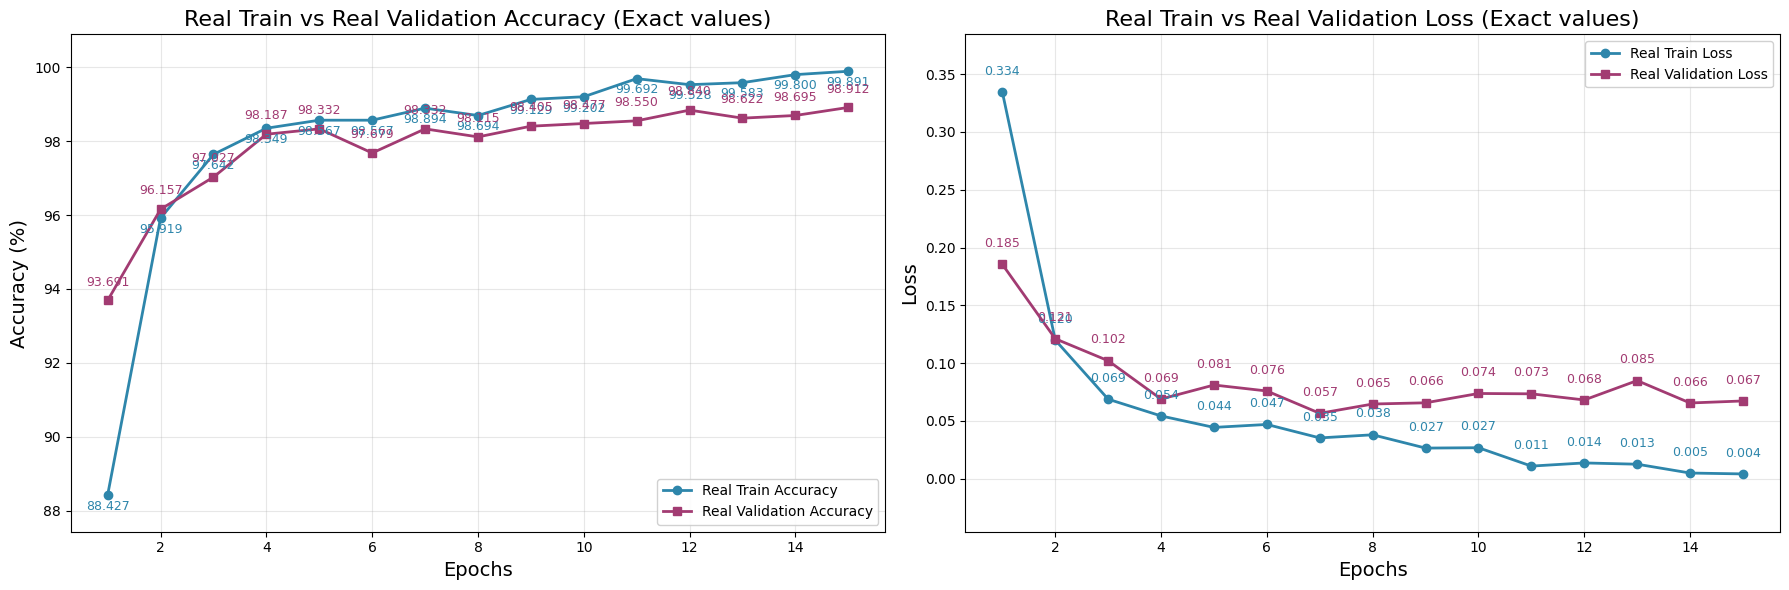

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# =========================
# Metrics
# =========================

train_acc = train_acc_history
val_acc = val_acc_history

train_loss = train_loss_history
val_loss = val_loss_history

epochs = range(1, len(train_acc) + 1)

# =========================
# Create Figure
# =========================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(18, 6)
)

# =========================================================
# LEFT SIDE → ACCURACY
# =========================================================

ax1.plot(
    epochs,
    train_acc,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Real Train Accuracy"
)

ax1.plot(
    epochs,
    val_acc,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Real Validation Accuracy"
)

# Accuracy annotations
for i in range(len(train_acc)):

    # Train accuracy text
    ax1.text(
        epochs[i],
        train_acc[i] - 0.4,
        f"{train_acc[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation accuracy text
    ax1.text(
        epochs[i],
        val_acc[i] + 0.4,
        f"{val_acc[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# Accuracy labels
ax1.set_title(
    "Real Train vs Real Validation Accuracy (Exact values)",
    fontsize=16
)

ax1.set_xlabel(
    "Epochs",
    fontsize=14
)

ax1.set_ylabel(
    "Accuracy (%)",
    fontsize=14
)

# Dynamic accuracy limits
acc_values = list(train_acc) + list(val_acc)

ax1.set_ylim(
    min(acc_values) - 1,
    max(acc_values) + 1
)

ax1.grid(alpha=0.3)

# =========================================================
# LEGEND → RIGHT BOTTOM
# =========================================================

ax1.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.9
)

# =========================================================
# RIGHT SIDE → LOSS
# =========================================================

ax2.plot(
    epochs,
    train_loss,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Real Train Loss"
)

ax2.plot(
    epochs,
    val_loss,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Real Validation Loss"
)

# Loss annotations
for i in range(len(train_loss)):

    # Train loss text
    ax2.text(
        epochs[i],
        train_loss[i] + 0.015,
        f"{train_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation loss text
    ax2.text(
        epochs[i],
        val_loss[i] + 0.015,
        f"{val_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# Loss labels
ax2.set_title(
    "Real Train vs Real Validation Loss (Exact values)",
    fontsize=16
)

ax2.set_xlabel(
    "Epochs",
    fontsize=14
)

ax2.set_ylabel(
    "Loss",
    fontsize=14
)

# Dynamic loss limits
loss_values = list(train_loss) + list(val_loss)

ax2.set_ylim(
    min(loss_values) - 0.05,
    max(loss_values) + 0.05
)

ax2.grid(alpha=0.3)

ax2.legend(
    loc="upper right",
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.9
)

# =========================
# Final Layout
# =========================

plt.tight_layout()
plt.show()

In [31]:

# ==========================================================
# 11. LOAD BEST MODEL
# ==========================================================

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Best checkpoint not found: {CHECKPOINT_PATH}"
    )

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

model.eval()

print("✓ Best model loaded successfully.")
print(f"Selected using REAL validation accuracy: {best_val_acc:.2f}%")
print("Synthetic test data has NOT been used for model selection.")


✓ Best model loaded successfully.
Selected using REAL validation accuracy: 98.91%
Synthetic test data has NOT been used for model selection.


In [32]:

# ==========================================================
# 12. FINAL SYNTHETIC TEST EVALUATION
# ==========================================================

test_loss, test_acc, y_pred, y_true, y_prob = evaluate(
    model,
    synthetic_test_loader
)

print("=" * 70)
print("FINAL SYNTHETIC TEST")
print("=" * 70)
print("Test domain      : SYNTHETIC")
print("Number of samples:", len(y_true))
print(f"Test Loss        : {test_loss:.4f}")
print(f"Test Accuracy    : {test_acc:.2f}%")


FINAL SYNTHETIC TEST
Test domain      : SYNTHETIC
Number of samples: 1116
Test Loss        : 0.1759
Test Accuracy    : 96.68%


In [33]:

# ==========================================================
# 13. CLASSIFICATION REPORT
# ==========================================================

print("=" * 70)
print("CLASSIFICATION REPORT — SYNTHETIC TEST")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


CLASSIFICATION REPORT — SYNTHETIC TEST
              precision    recall  f1-score   support

      glioma     0.9488    0.9893    0.9686       281
  meningioma     0.9959    0.9240    0.9586       263
     notumor     0.9966    0.9637    0.9799       303
   pituitary     0.9301    0.9888    0.9586       269

    accuracy                         0.9668      1116
   macro avg     0.9678    0.9665    0.9664      1116
weighted avg     0.9684    0.9668    0.9669      1116



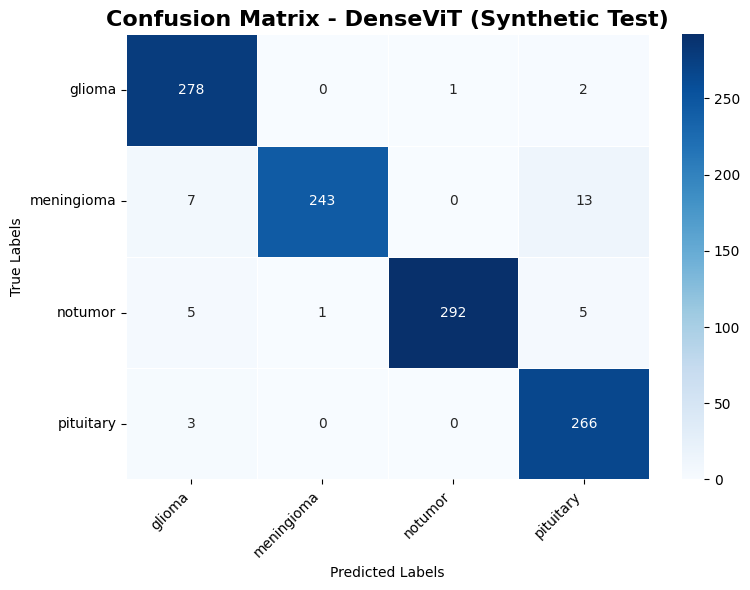

Confusion Matrix:
[[278   0   1   2]
 [  7 243   0  13]
 [  5   1 292   5]
 [  3   0   0 266]]


In [34]:

# ==========================================================
# 14. CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    linewidths=0.5,
    linecolor="white"
)

plt.title(
    "Confusion Matrix - DenseViT (Synthetic Test)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)


In [35]:

# ==========================================================
# 15. FINAL METRICS + SPECIFICITY + MCC
# ==========================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)

specificities = []

for i in range(len(class_names)):

    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)

    specificity = (
        TN / (TN + FP)
        if (TN + FP) > 0
        else 0.0
    )

    specificities.append(specificity)

macro_specificity = float(
    np.mean(specificities)
)

print("=" * 70)
print("FINAL DENSViT SYNTHETIC-TEST METRICS")
print("=" * 70)

print(f"Accuracy           : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision (weighted): {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall (weighted)   : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score (weighted) : {f1:.4f} ({f1*100:.2f}%)")
print(f"MCC                 : {mcc:.4f}")
print(f"Macro Specificity   : {macro_specificity:.4f}")

print("\nClass-wise Specificity:")

for name, spec in zip(class_names, specificities):
    print(f"{name:15s}: {spec:.4f}")


FINAL DENSViT SYNTHETIC-TEST METRICS
Accuracy           : 0.9668 (96.68%)
Precision (weighted): 0.9684 (96.84%)
Recall (weighted)   : 0.9668 (96.68%)
F1 Score (weighted) : 0.9669 (96.69%)
MCC                 : 0.9562
Macro Specificity   : 0.9890

Class-wise Specificity:
glioma         : 0.9820
meningioma     : 0.9988
notumor        : 0.9988
pituitary      : 0.9764


In [36]:

# ==========================================================
# 16. PREDICTION DISTRIBUTION DIAGNOSTIC
# ==========================================================

print("=" * 70)
print("SYNTHETIC TEST PREDICTION DISTRIBUTION")
print("=" * 70)

unique, counts = np.unique(
    y_pred,
    return_counts=True
)

pred_counts = dict(
    zip(unique, counts)
)

for idx, name in enumerate(class_names):

    count = pred_counts.get(idx, 0)

    print(
        f"{name:15s}: "
        f"{count:4d} images "
        f"({count / len(y_pred) * 100:6.2f}%)"
    )


SYNTHETIC TEST PREDICTION DISTRIBUTION
glioma         :  293 images ( 26.25%)
meningioma     :  244 images ( 21.86%)
notumor        :  293 images ( 26.25%)
pituitary      :  286 images ( 25.63%)


ROC-AUC — SYNTHETIC TEST
Micro-average ROC-AUC: 0.9983
glioma         : 0.9992
meningioma     : 0.9987
notumor        : 0.9987
pituitary      : 0.9985


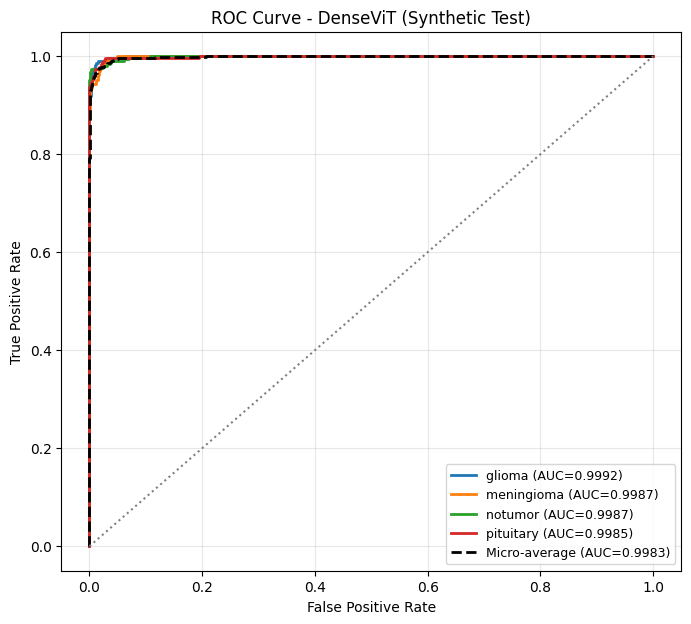

In [37]:

# ==========================================================
# 17. MULTICLASS ROC-AUC — SYNTHETIC TEST
# ==========================================================

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

fpr = {}
tpr = {}
roc_auc = {}

for i in range(len(class_names)):

    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# Micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(
    y_true_bin.ravel(),
    y_prob.ravel()
)

roc_auc["micro"] = auc(
    fpr["micro"],
    tpr["micro"]
)

print("=" * 70)
print("ROC-AUC — SYNTHETIC TEST")
print("=" * 70)

print(
    f"Micro-average ROC-AUC: "
    f"{roc_auc['micro']:.4f}"
)

for i, name in enumerate(class_names):
    print(
        f"{name:15s}: "
        f"{roc_auc[i]:.4f}"
    )

plt.figure(figsize=(8, 7))

for i, name in enumerate(class_names):

    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=2,
        label=f"{name} (AUC={roc_auc[i]:.4f})"
    )

plt.plot(
    fpr["micro"],
    tpr["micro"],
    linestyle="--",
    linewidth=2,
    color="black",
    label=f"Micro-average (AUC={roc_auc['micro']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle=":",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "ROC Curve - DenseViT (Synthetic Test)"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(alpha=0.3)
plt.show()


In [38]:

# ==========================================================
# 18. PARAMETER COUNT + INFERENCE TIME
# ==========================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

non_trainable_params = (
    total_params - trainable_params
)

print("=" * 70)
print("MODEL COMPLEXITY")
print("=" * 70)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")
print(f"Non-trainable Params : {non_trainable_params:,}")


# ----------------------------------------------------------
# Single-image latency
# ----------------------------------------------------------

model.eval()

sample_images, _ = next(iter(synthetic_test_loader))

single_image = sample_images[0:1].to(device)

# Warm-up
with torch.no_grad():
    for _ in range(5):
        _ = model(single_image)

if torch.cuda.is_available():
    torch.cuda.synchronize()

latencies = []

with torch.no_grad():

    for _ in range(20):

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = model(single_image)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end = time.perf_counter()

        latencies.append(
            (end - start) * 1000
        )

latency_ms = float(np.mean(latencies))
latency_std_ms = float(np.std(latencies))

print(f"Single-image Latency : {latency_ms:.3f} ± {latency_std_ms:.3f} ms")


# ----------------------------------------------------------
# Full synthetic-test inference
# ----------------------------------------------------------

synthetic_test_loader_for_timing = DataLoader(
    synthetic_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.no_grad():
    for images, _ in synthetic_test_loader_for_timing:
        images = images.to(device)
        _ = model(images)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

inference_time = time.perf_counter() - start

fps = (
    len(synthetic_test_dataset) / inference_time
    if inference_time > 0
    else 0
)

print(f"Synthetic Test Inference Time: {inference_time:.4f} s")
print(f"Throughput (FPS)              : {fps:.2f}")


MODEL COMPLEXITY
Total Parameters     : 19,092,036
Trainable Parameters : 19,092,036
Non-trainable Params : 0
Single-image Latency : 30.958 ± 6.287 ms
Synthetic Test Inference Time: 6.0999 s
Throughput (FPS)              : 182.96


In [39]:

# ==========================================================
# 19. FINAL EXPERIMENT SUMMARY
# ==========================================================

print("\n" + "=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)

print("Experiment : TRAIN REAL → VALIDATE REAL → TEST SYNTHETIC")
print("Model      : DenseNet169 + ViT-Tiny")
print("Input      : 224 × 224 × 3")
print("Classes    :", class_names)

print("\nDataset:")
print(f"  Real Train       : {len(train_dataset)}")
print(f"  Real Validation  : {len(val_dataset)}")
print(f"  Synthetic Test   : {len(synthetic_test_dataset)}")

print("\nPerformance:")
print(f"  Best Real Val Accuracy : {best_val_acc:.2f}%")
print(f"  Synthetic Test Accuracy: {accuracy*100:.2f}%")
print(f"  Synthetic Test Precision: {precision*100:.2f}%")
print(f"  Synthetic Test Recall   : {recall*100:.2f}%")
print(f"  Synthetic Test F1       : {f1*100:.2f}%")
print(f"  Synthetic Test MCC      : {mcc:.4f}")

print("\nImportant:")
print("  ✓ Training used REAL images only.")
print("  ✓ Model selection used REAL validation only.")
print("  ✓ Synthetic test was kept completely outside training.")
print("  ✓ Synthetic test was evaluated only after loading the best REAL-validation checkpoint.")



FINAL EXPERIMENT SUMMARY
Experiment : TRAIN REAL → VALIDATE REAL → TEST SYNTHETIC
Model      : DenseNet169 + ViT-Tiny
Input      : 224 × 224 × 3
Classes    : ['glioma', 'meningioma', 'notumor', 'pituitary']

Dataset:
  Real Train       : 5513
  Real Validation  : 1379
  Synthetic Test   : 1116

Performance:
  Best Real Val Accuracy : 98.91%
  Synthetic Test Accuracy: 96.68%
  Synthetic Test Precision: 96.84%
  Synthetic Test Recall   : 96.68%
  Synthetic Test F1       : 96.69%
  Synthetic Test MCC      : 0.9562

Important:
  ✓ Training used REAL images only.
  ✓ Model selection used REAL validation only.
  ✓ Synthetic test was kept completely outside training.
  ✓ Synthetic test was evaluated only after loading the best REAL-validation checkpoint.
